# Finding Transit Gaps in NYC: baseline and Random Forest

<a href="https://colab.research.google.com/github/hrb9339/nyc-transit-3d/blob/main/notebooks/01_baseline_random_forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Task.** Predict average weekday subway ridership (2025 entries) of a station from the place around it. A model that does this well can then score places with no station: the 1,080 candidate hexagons.

**Data.** `data/model/training.csv`: 424 subway station complexes, each with the 120 features of the 500 m hexagon it sits in (people, jobs, land use, income and cars, bus and other rail service, street network, night lights, distance to Midtown, nearby stations). Built by the repo's `scripts/`; column roles in `data/model/feature_columns.csv`.

**Target.** `log_weekday_riders` = log(1 + riders). Ridership runs from about 200 to 148,000 a day, so errors are measured on the log scale (an error of 0.1 is about 10%).

**Evaluation.** 5-fold cross-validation grouped by neighborhood (2020 NTA): all stations of a neighborhood are in the same fold. Nearby stations share features, so a random split would let the model memorize neighbors and overstate accuracy. Metrics: R², MAE and RMSE on the log scale, and the median percentage error in riders.

**Plan in this notebook.**
1. Baselines: predict the mean; linear models
2. Random Forest v1
3. Experiment: tree settings
4. Experiment: ablation by feature group
5. Feature importance
6. Failure analysis

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

BASE = "https://raw.githubusercontent.com/hrb9339/nyc-transit-3d/main/data/"
SEED = 42
warnings.filterwarnings("ignore", category=UserWarning)
os.environ["PYTHONWARNINGS"] = "ignore::UserWarning"
print("scikit-learn", sklearn.__version__)

scikit-learn 1.9.1


## 0. Load the data

In [2]:
cols = pd.read_csv(BASE + "model/feature_columns.csv")
FEATURES = cols.loc[cols.role == "feature", "column"].tolist()
train = pd.read_csv(BASE + "model/training.csv", comment="#")

X = train[FEATURES]
y = train["log_weekday_riders"].to_numpy()
groups = train["nta2020"].to_numpy()

print(f"{len(train)} stations, {len(FEATURES)} features, {train.nta2020.nunique()} neighborhoods")
print("stations per borough:", train.borough.value_counts().to_dict())
print("missing values:", int(X.isna().sum().sum()), "cells")
print(cols.role.value_counts().to_dict())

424 stations, 120 features, 143 neighborhoods
stations per borough: {'Brooklyn': 155, 'Manhattan': 121, 'Queens': 80, 'Bronx': 68}
missing values: 14 cells
{'feature': 120, 'excluded': 10, 'info': 10, 'id': 2, 'target': 2, 'group': 2, 'ranking': 2}


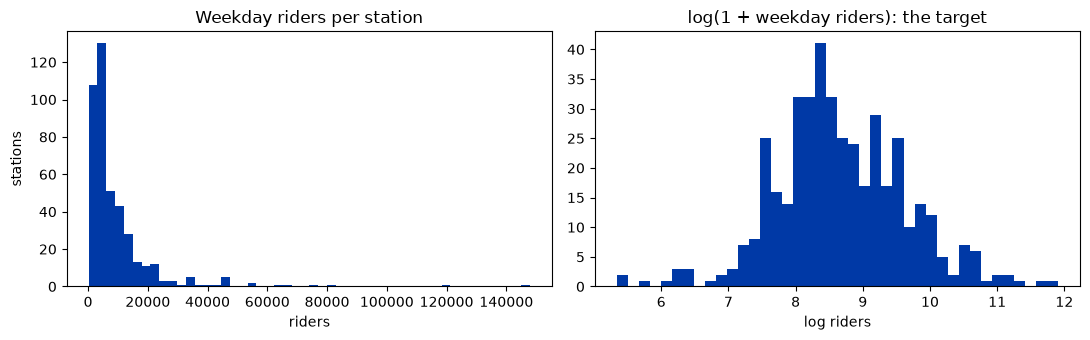

count       424.0
mean       9614.0
std       13704.0
min         207.0
25%        3127.0
50%        5257.0
75%       10659.0
max      147887.0
Name: weekday_riders, dtype: float64

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(train.weekday_riders, bins=50, color="#0039a6")
ax[0].set(title="Weekday riders per station", xlabel="riders", ylabel="stations")
ax[1].hist(y, bins=40, color="#0039a6")
ax[1].set(title="log(1 + weekday riders): the target", xlabel="log riders")
plt.tight_layout()
plt.show()
train.weekday_riders.describe().round(0)

## Evaluation helper

Every model goes through the same function: the same 5 neighborhood folds, out-of-fold predictions for every station, and the same metrics. Imputation and scaling are inside the pipeline, so they are fitted on the training folds only.

In [4]:
CV = GroupKFold(n_splits=5)
FOLDS = list(CV.split(X, y, groups))


def evaluate(model, Xm=X, name=None):
    pred = np.zeros(len(y))
    fold_r2 = []
    for tr, te in FOLDS:
        model.fit(Xm.iloc[tr], y[tr])
        pred[te] = model.predict(Xm.iloc[te])
        fold_r2.append(r2_score(y[te], pred[te]))
    riders, riders_hat = np.expm1(y), np.expm1(pred)
    row = {
        "model": name,
        "R2": r2_score(y, pred),
        "R2_fold_sd": np.std(fold_r2),
        "MAE_log": mean_absolute_error(y, pred),
        "RMSE_log": mean_squared_error(y, pred) ** 0.5,
        "median_pct_error": np.median(np.abs(riders_hat - riders) / riders) * 100,
    }
    return row, pred


results = []

## 1. Baselines

- **Mean**: predicts the average log ridership for every station. Any useful model must beat it.
- **Linear, 3 features**: job density, population density and distance to Midtown, the three things a planner would check first.
- **Ridge, all features**: a linear model with every feature (standardized, with cross-validated regularization), to see how far a linear model gets.

In [5]:
SIMPLE = ["job_density", "pop_density", "km_to_midtown"]
X_simple = X[SIMPLE].assign(job_density=np.log1p(X.job_density), pop_density=np.log1p(X.pop_density))

for name, model, Xm in [
    ("Mean", DummyRegressor(), X),
    ("Linear, 3 features", make_pipeline(SimpleImputer(strategy="median"), LinearRegression()), X_simple),
    ("Ridge, all features", make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                          RidgeCV(alphas=np.logspace(-2, 4, 30))), X),
]:
    row, _ = evaluate(model, Xm, name)
    results.append(row)

pd.DataFrame(results).round(3)

,model,R2,R2_fold_sd,MAE_log,RMSE_log,median_pct_error
0,Mean,-0.003,0.007,0.760,0.979,57.601
1,"Linear, 3 features",0.484,0.095,0.529,0.702,38.760
2,"Ridge, all features",0.434,0.357,0.511,0.735,38.052


**Baseline results.**
- The mean model scores R² = -0.003 with a median error of 57.6%: the floor.
- Three features (jobs, people, distance to Midtown) already reach R² = 0.484 and cut the median error to 38.8%. Most of the predictable variation is "how busy is the area and how close is it to Midtown".
- Ridge with all 120 features does **worse** (R² = 0.434) and is unstable across folds (SD 0.357 vs 0.095). With 424 stations, many correlated features and one model per neighborhood fold, a linear model overfits some folds badly. More features only help with a model that can pick among them.

## 2. Random Forest v1

Default-style forest: 300 trees, every feature allowed at each split, leaves of at least 1 station. Missing values (one station has no ACS data) are filled with the training-fold median.

In [6]:
def rf(**kw):
    params = dict(n_estimators=300, random_state=SEED, n_jobs=-1)
    params.update(kw)
    return make_pipeline(SimpleImputer(strategy="median"), RandomForestRegressor(**params))


row, pred_rf1 = evaluate(rf(), X, "Random Forest v1 (defaults)")
results.append(row)
pd.DataFrame(results).round(3)

,model,R2,R2_fold_sd,MAE_log,RMSE_log,median_pct_error
0,Mean,-0.003,0.007,0.760,0.979,57.601
1,"Linear, 3 features",0.484,0.095,0.529,0.702,38.760
2,"Ridge, all features",0.434,0.357,0.511,0.735,38.052
3,Random Forest v1 (defaults),0.560,0.060,0.503,0.648,38.930


**Random Forest v1** reaches R² = 0.560, beating the best baseline (0.484), with lower RMSE (0.648 vs 0.702) and MAE (0.503 vs 0.529), and steadier folds (SD 0.060). The median error is about the same as the 3-feature model (38.9% vs 38.8%): the forest's gain is mostly on the large misses (RMSE), not the typical station.

## 3. Experiment: tree settings

With only 424 stations and 120 features, deep trees that consider every feature can overfit. This grid varies how many features each split may look at (`max_features`) and how small a leaf can be (`min_samples_leaf`). Each setting is scored with the same neighborhood folds.

In [7]:
grid = []
for max_features in [1.0, 0.5, 0.33, "sqrt"]:
    for min_leaf in [1, 3, 5, 10]:
        row, _ = evaluate(rf(max_features=max_features, min_samples_leaf=min_leaf), X)
        grid.append({"max_features": str(max_features), "min_samples_leaf": min_leaf,
                     "R2": row["R2"], "MAE_log": row["MAE_log"]})
grid = pd.DataFrame(grid)
grid.pivot(index="max_features", columns="min_samples_leaf", values="R2").round(3)

min_samples_leaf,1,3,5,10
max_features,,,,
0.33,0.565,0.550,0.540,0.523
0.5,0.567,0.551,0.544,0.526
1.0,0.560,0.550,0.542,0.527
sqrt,0.547,0.532,0.531,0.512


In [8]:
best = grid.sort_values("R2", ascending=False).iloc[0]
mf = best.max_features
BEST = dict(max_features=float(mf) if mf.replace(".", "").isdigit() else mf, min_samples_leaf=int(best.min_samples_leaf))
print("best setting:", BEST)

row, pred_rf2 = evaluate(rf(**BEST), X, f"Random Forest tuned {BEST}")
results.append(row)
pd.DataFrame(results).round(3)

best setting: {'max_features': 0.5, 'min_samples_leaf': 1}


,model,R2,R2_fold_sd,MAE_log,RMSE_log,median_pct_error
0,Mean,-0.003,0.007,0.760,0.979,57.601
1,"Linear, 3 features",0.484,0.095,0.529,0.702,38.760
2,"Ridge, all features",0.434,0.357,0.511,0.735,38.052
3,Random Forest v1 (defaults),0.560,0.060,0.503,0.648,38.930
4,"Random Forest tuned {'max_features': 0.5, 'min...",0.567,0.074,0.495,0.643,38.488


**Tree-settings result.** R² ranges from 0.512 to 0.567 across the 16 settings. Smaller leaves are better in every row (leaf 1 > 3 > 5 > 10), and `sqrt` (about 11 features per split) is the worst row. The best, `max_features=0.5, min_samples_leaf=1`, gives R² = 0.567, only +0.007 over the defaults. **Hyperparameters are not the bottleneck; the features are**, which the next two experiments look at.

**Caveat.** The settings were picked on the same folds they are scored on, so the tuned score is slightly optimistic. With 424 stations a separate tuning set would leave too little data; nested cross-validation is the fix if the gain matters.

## 4. Experiment: ablation by feature group

Which data actually helps? Each run removes one group of features (one source table) and re-scores the tuned forest. A big drop means the group carries information the others don't.

In [9]:
TABLES = ["demographics", "acs", "landuse", "destinations", "ntl_trend", "bus", "rail", "walk", "midtown",
          "neighborhoods"]
table_cols = {}
for t in TABLES:
    header = pd.read_csv(BASE + f"features/{t}.csv", comment="#", nrows=0).columns
    table_cols[t] = [c for c in header if c in FEATURES]

GROUPS = {
    "people & jobs (Census, LODES)": table_cols["demographics"],
    "income, cars, commuting (ACS)": table_cols["acs"],
    "land use & buildings (PLUTO)": table_cols["landuse"],
    "destinations": table_cols["destinations"],
    "night lights (VIIRS)": table_cols["ntl_trend"] + ["ntl_mean", "ntl_sum", "ntl_density", "lit_pixels", "bright_pixels"],
    "bus service": table_cols["bus"],
    "other rail (LIRR, MNR, PATH)": table_cols["rail"],
    "street network": table_cols["walk"],
    "distance to Midtown/downtown": table_cols["midtown"],
    "nearby stations (competition)": ["other_stations_1km", "nearest_other_station_m"],
    "borough & area": [c for c in FEATURES if c.startswith("boro_")] + ["land_km2"] + table_cols["neighborhoods"],
}
grouped = {c for g in GROUPS.values() for c in g}
print("features not in any group:", sorted(set(FEATURES) - grouped))
pd.Series({g: len(c) for g, c in GROUPS.items()}, name="features")

features not in any group: []


people & jobs (Census, LODES)     4
income, cars, commuting (ACS)    19
land use & buildings (PLUTO)     25
destinations                     14
night lights (VIIRS)             22
bus service                      10
other rail (LIRR, MNR, PATH)     11
street network                    5
distance to Midtown/downtown      2
nearby stations (competition)     2
borough & area                    6
Name: features, dtype: int64

In [10]:
full, _ = evaluate(rf(**BEST), X)
abl = []
for g, gcols in GROUPS.items():
    row, _ = evaluate(rf(**BEST), X.drop(columns=gcols))
    only, _ = evaluate(rf(**BEST), X[gcols])
    abl.append({"group": g, "features": len(gcols), "R2_without": row["R2"],
                "drop_in_R2": full["R2"] - row["R2"], "R2_this_group_only": only["R2"]})
abl = pd.DataFrame(abl).sort_values("drop_in_R2", ascending=False)
print(f"all features: R2 = {full['R2']:.3f}")
abl.round(3)

all features: R2 = 0.567


,group,features,R2_without,drop_in_R2,R2_this_group_only
9,nearby stations (competition),2,0.533,0.034,-0.086
1,"income, cars, commuting (ACS)",19,0.550,0.017,0.445
2,land use & buildings (PLUTO),25,0.552,0.015,0.487
0,"people & jobs (Census, LODES)",4,0.558,0.009,0.349
7,street network,5,0.558,0.009,0.030
8,distance to Midtown/downtown,2,0.560,0.007,0.372
6,"other rail (LIRR, MNR, PATH)",11,0.561,0.006,0.274
4,night lights (VIIRS),22,0.563,0.004,0.235
3,destinations,14,0.565,0.002,0.272
10,borough & area,6,0.565,0.002,0.171


**Ablation result.** Removing any single group costs at most 0.034 R², so the groups largely overlap: most of what one table says (busy place, dense buildings, low car use) is also said by another.
- **Nearby stations** is the only group with a clear unique contribution (0.567 → 0.533), even though on its own it is useless (R² = -0.086). The distance to the next station only matters once the model knows how busy the area is: close neighbours split the same riders.
- **ACS** (drop 0.017) and **land use** (drop 0.015) come next. Land use alone (R² = 0.487) already matches the 3-feature baseline, and ACS alone reaches 0.445.
- **Bus service, destinations and borough** add almost nothing (drop 0.002 each). They are candidates to remove for a simpler model.
- The street network barely predicts on its own (0.030) but still adds 0.009 on top of the rest.

## 5. Feature importance

Permutation importance on held-out folds: shuffle one feature in the test fold and measure how much R² falls, averaged over the 5 folds. Unlike the forest's built-in importance, this is measured on stations the model did not see, and it isn't biased toward features with many distinct values. Correlated features share credit (shuffling one leaves its twin), which is why the ablation above is the better test for whole groups.

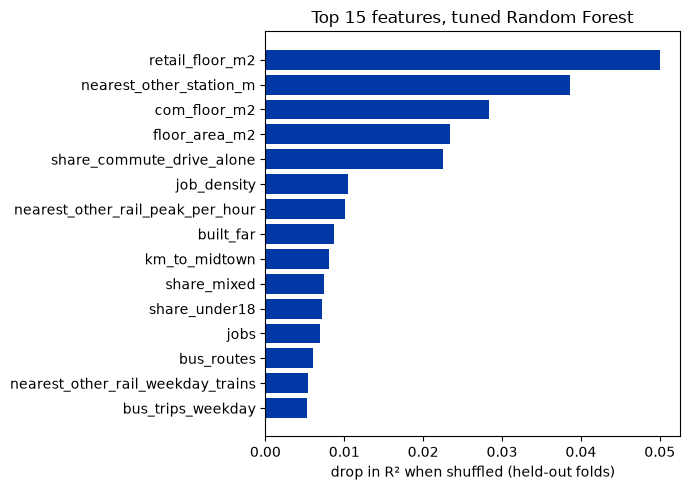

retail_floor_m2                      0.0501
nearest_other_station_m              0.0386
com_floor_m2                         0.0283
floor_area_m2                        0.0234
share_commute_drive_alone            0.0226
job_density                          0.0105
nearest_other_rail_peak_per_hour     0.0100
built_far                            0.0087
km_to_midtown                        0.0081
share_mixed                          0.0074
share_under18                        0.0072
jobs                                 0.0069
bus_routes                           0.0060
nearest_other_rail_weekday_trains    0.0054
bus_trips_weekday                    0.0053
dtype: float64

In [11]:
imp = []
for tr, te in FOLDS:
    m = rf(**BEST).fit(X.iloc[tr], y[tr])
    r = permutation_importance(m, X.iloc[te], y[te], n_repeats=3, random_state=SEED, scoring="r2")
    imp.append(r.importances_mean)
imp = pd.Series(np.mean(imp, axis=0), index=FEATURES).sort_values(ascending=False)

top = imp.head(15)[::-1]
plt.figure(figsize=(7, 5))
plt.barh(top.index, top.values, color="#0039a6")
plt.xlabel("drop in R² when shuffled (held-out folds)")
plt.title("Top 15 features, tuned Random Forest")
plt.tight_layout()
plt.show()
imp.head(15).round(4)

**Importance result.** The top five are retail floor area (0.0501), distance to the nearest other station (0.0386), commercial floor area (0.0283), total floor area (0.0234) and the share of workers who drive alone (0.0226). This is sensible: shops and offices are where trips start and end, closely spaced stations share riders, and car-dependent areas ride less. Everything after the top five is below 0.011 because correlated features share credit, consistent with the ablation.

## 6. Failure analysis

Out-of-fold predictions of the tuned forest: every station is predicted by a model that never saw its neighborhood.

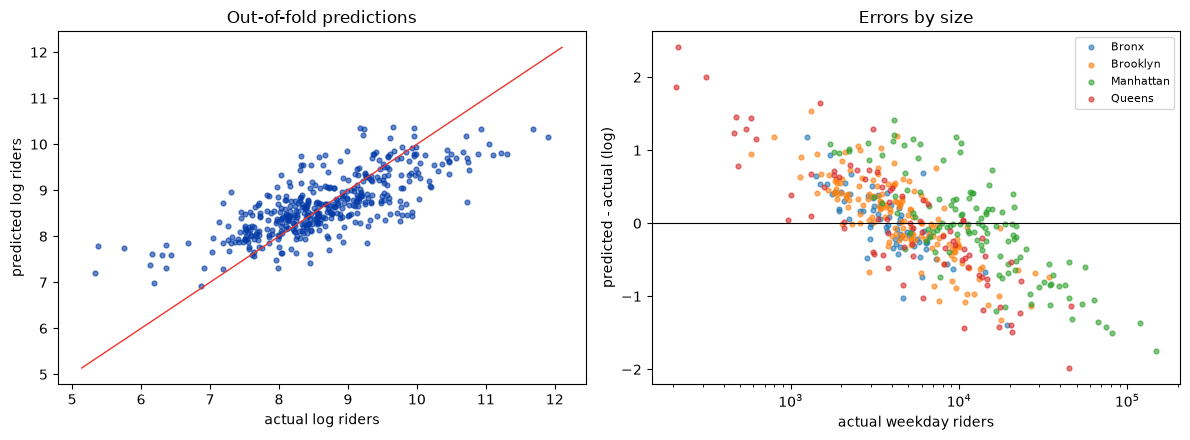

In [12]:
res = train[["station_complex", "borough", "weekday_riders", "complexes_in_hex", "days_with_data",
             "ride_minutes_to_midtown"]].copy()
res["predicted"] = np.expm1(pred_rf2).round(0)
res["log_error"] = pred_rf2 - y
res["lines"] = res.station_complex.str.extract(r"\(([^)]*)\)")[0].str.count(",") + 1

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(y, pred_rf2, s=12, alpha=0.6, color="#0039a6")
lim = [y.min() - 0.2, y.max() + 0.2]
ax[0].plot(lim, lim, color="#ee352e", lw=1)
ax[0].set(xlabel="actual log riders", ylabel="predicted log riders", title="Out-of-fold predictions")
for b, g in res.groupby("borough"):
    ax[1].scatter(g.weekday_riders, g.log_error, s=12, alpha=0.6, label=b)
ax[1].axhline(0, color="black", lw=0.8)
ax[1].set(xscale="log", xlabel="actual weekday riders", ylabel="predicted - actual (log)", title="Errors by size")
ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [13]:
show = ["station_complex", "borough", "weekday_riders", "predicted", "log_error", "lines"]
print("Most UNDER-predicted (busier than the model expects):")
display(res.sort_values("log_error").head(10)[show].round(2))
print("Most OVER-predicted (quieter than the model expects):")
display(res.sort_values("log_error", ascending=False).head(10)[show].round(2))

Most UNDER-predicted (busier than the model expects):


,station_complex,borough,weekday_riders,predicted,log_error,lines
10,"Jackson Hts-Roosevelt Av/74 St-Broadway (7,E,F...",Queens,45235.0,6232.0,-1.98,5
0,"Times Sq-42 St/Port Authority Bus Terminal (1,...",Manhattan,147887.0,25842.0,-1.74,12
2,"34 St-Herald Sq (B,D,F,M,N,Q,R,W)",Manhattan,80826.0,17872.0,-1.51,8
41,Junction Blvd (7),Queens,20537.0,4663.0,-1.48,1
106,111 St (7),Queens,10641.0,2547.0,-1.43,1
3,"14 St-Union Sq (4,5,6,L,N,Q,R,W)",Manhattan,74263.0,18008.0,-1.42,8
57,"Kew Gardens-Union Tpke (E,F)",Queens,17256.0,4186.0,-1.42,2
42,"Forest Hills-71 Av (E,F,M,R)",Queens,20413.0,5090.0,-1.39,4
47,"161 St-Yankee Stadium (4,B,D)",Bronx,19167.0,4781.0,-1.39,3
1,"Grand Central-42 St (4,5,6,7,S)",Manhattan,119396.0,30405.0,-1.37,5


Most OVER-predicted (quieter than the model expects):


,station_complex,borough,weekday_riders,predicted,log_error,lines
422,"Beach 105 St (A,S)",Queens,215.0,2401.0,2.41,2
421,"Beach 98 St (A,S)",Queens,312.0,2303.0,2.00,2
423,"Broad Channel (A,S)",Queens,207.0,1336.0,1.86,2
400,21 St (G),Queens,1494.0,7774.0,1.65,1
405,Park Pl (S),Brooklyn,1324.0,6161.0,1.54,1
419,Aqueduct Racetrack (A),Queens,472.0,2033.0,1.46,1
416,"Rockaway Park-Beach 116 St (A,S)",Queens,581.0,2447.0,1.44,2
267,Canal St (1),Manhattan,4108.0,16987.0,1.42,1
417,"Beach 90 St (A,S)",Queens,543.0,1989.0,1.30,2
323,"39 Av-Dutch Kills (N,W)",Queens,3087.0,11218.0,1.29,2


In [14]:
res["size"] = pd.qcut(res.weekday_riders, 4, labels=["smallest 25%", "25-50%", "50-75%", "busiest 25%"])
res["lines_served"] = pd.cut(res.lines, [0, 1, 2, 4, 20], labels=["1 line", "2 lines", "3-4 lines", "5+ lines"])
summary = pd.concat({
    "by size": res.groupby("size", observed=True).log_error.agg(["count", "mean", lambda e: e.abs().mean()]),
    "by lines served": res.groupby("lines_served", observed=True).log_error.agg(["count", "mean", lambda e: e.abs().mean()]),
    "by borough": res.groupby("borough").log_error.agg(["count", "mean", lambda e: e.abs().mean()]),
})
summary.columns = ["stations", "mean error (bias)", "mean |error|"]
summary.round(3)

stations  mean error (bias)  mean |error|
by size         smallest 25%       106              0.579         0.615
                25-50%             106              0.168         0.348
                50-75%             106             -0.107         0.361
                busiest 25%        106             -0.569         0.656
by lines served 1 line             237              0.135         0.429
                2 lines            130              0.136         0.487
                3-4 lines           38             -0.592         0.665
                5+ lines            19             -1.035         1.035
by borough      Bronx               68              0.013         0.343
                Brooklyn           155              0.078         0.435
                Manhattan          121             -0.050         0.539
                Queens              80              0.009         0.676

**Failure analysis.**
1. **Transfer hubs are badly under-predicted.** Stations served by 5+ lines have a mean log error of -1.035: real ridership is about 2.8× the prediction. Times Sq is predicted at 25,842 against 147,887; Jackson Hts-Roosevelt Av (7, E, F, M, R plus LaGuardia buses) at 6,232 against 45,235. These stations draw riders from the whole network, which none of our features describe: they only describe the hexagon around the station.
2. **The model shrinks toward the middle.** The busiest quarter is predicted too low (bias -0.569, about 43% low) and the quietest quarter too high (+0.579, about 1.8× too high). This is typical of averaging trees with limited data, and it is worst exactly where the extremes are hubs or special cases.
3. **Special-case quiet stations.** The over-predicted list is mostly Rockaway stations (Beach 105 St, Beach 98 St, Broad Channel, Beach 116 St, Beach 90 St), which were closed for part of 2025 and serve a seasonal beach area, plus single-purpose or short-line stops (Aqueduct Racetrack, Park Pl shuttle, 21 St on the G).
4. **Queens has the largest errors** (mean |error| 0.676 vs 0.343 in the Bronx): it has both the big hubs (Jackson Hts, Forest Hills, Kew Gardens) and the Rockaways. The 7-line stops (Junction Blvd, 111 St) are also under-predicted, all being single-line stations in very dense, low-car neighborhoods.

## Results so far

In [15]:
pd.DataFrame(results).round(3)

,model,R2,R2_fold_sd,MAE_log,RMSE_log,median_pct_error
0,Mean,-0.003,0.007,0.760,0.979,57.601
1,"Linear, 3 features",0.484,0.095,0.529,0.702,38.760
2,"Ridge, all features",0.434,0.357,0.511,0.735,38.052
3,Random Forest v1 (defaults),0.560,0.060,0.503,0.648,38.930
4,"Random Forest tuned {'max_features': 0.5, 'min...",0.567,0.074,0.495,0.643,38.488


## Summary and next experiments

| Model | R² | Median % error |
|---|---|---|
| Mean | -0.003 | 57.6 |
| Linear, 3 features | 0.484 | 38.8 |
| Ridge, all features | 0.434 | 38.1 |
| Random Forest v1 | 0.560 | 38.9 |
| Random Forest tuned | 0.567 | 38.5 |

The Random Forest beats every baseline on R² and RMSE. Tuning adds little, and the error analysis points to one missing piece of information: **where the station sits in the subway network**.

Next experiments, in priority order:
1. **Network features** (fixes failure 1): number of lines served, express stop, transfer station, and lines reachable without a transfer, from `data/subway-stations.geojson` routes and `data/network.json`. Success = the 5+ lines bias moves toward 0 and R² rises.
2. **Closures and outliers** (failure 3): drop or flag stations with `days_with_data` < 300 (the Rockaways), or train on `weekday_riders_median`; report R² with and without.
3. **Simpler model**: drop the groups that add ≤ 0.002 (bus, destinations, borough) and check the score holds.
4. **Other models**: gradient boosting (HistGradientBoostingRegressor) against the forest on the same folds; nested CV for honest tuning.
5. **Back-test**: hold out the Second Avenue Subway stations (72 St, 86 St, 96 St on the Q, opened 2017) and predict them as if they were new.
6. **Ranking**: score `data/model/candidates.csv` and rank by predicted riders × `uncovered_share_any_rail`.

Runtime: about 10 minutes on a laptop (the ablation and permutation steps are most of it).